# ADP 23회 상황형 연습 - 풀이

**상황형 재구성 연습·예시 풀이이며 공식 원문/정답이 아닙니다.**

출처: DataManim ADP 23회 실기 문제 PDF

원 자료 조건: 첨부 자료의 문항·표·그림을 바탕으로 정리한 학습용 자료입니다.

문제는 동봉 상황형 문제지와 같습니다. 원문은 문항목록.json·추가_문항명세.json에 보존합니다. 순서대로 실행하며 각 대문항에서 고정한 자료·전처리·분할을 후속 문항에 재사용합니다. 통계 답안은 선정 근거 → 가정·가설 → 통계량·p-value → 기각 여부·상황 해석 순서로 작성합니다. 확률·구간 추정·관리도 문항에 불필요한 귀무가설을 만들지 않습니다.

실행: 해당 회차 폴더에서 위에서 아래로 실행합니다. 가설검정_답안.json은 실제 계산한 가설·수치·결론 기록입니다.

In [1]:
from pathlib import Path
import sys, platform, time, inspect, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
from IPython.display import display, Markdown
from scipy import stats
import statsmodels.api as sm
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.model_selection import train_test_split, StratifiedKFold, KFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression, LinearRegression, RidgeCV
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVC, SVR
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score, confusion_matrix,
    roc_auc_score, average_precision_score, mean_squared_error, mean_absolute_error, r2_score,
    silhouette_score)
from sklearn.inspection import permutation_importance
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.oneway import anova_oneway
from imblearn.over_sampling import RandomOverSampler, SMOTE
from imblearn.under_sampling import RandomUnderSampler
from imblearn.pipeline import Pipeline as ImbPipeline

SEED = 42
HERE = Path.cwd()
DATA = HERE / 'data'
assert DATA.is_dir(), '압축을 전체 해제한 뒤, 노트북이 있는 회차 폴더를 작업 위치로 실행하세요.'
OUT = HERE / '실행결과'
OUT.mkdir(exist_ok=True)
font_path = HERE.parent / '공통' / 'NanumGothic-Regular.ttf'
if font_path.is_file():
    font_manager.fontManager.addfont(str(font_path))
    plt.rcParams['font.family'] = font_manager.FontProperties(fname=str(font_path)).get_name()
plt.rcParams.update({'axes.unicode_minus': False, 'figure.dpi': 110, 'font.size': 10})
pd.set_option('display.max_columns', 12)
pd.set_option('display.max_rows', 20)
print('Python', platform.python_version())
import sklearn, scipy, statsmodels, imblearn
print('numpy', np.__version__, 'pandas', pd.__version__, 'scikit-learn', sklearn.__version__,
      'scipy', scipy.__version__, 'statsmodels', statsmodels.__version__, 'imblearn', imblearn.__version__)

def load(name):
    return pd.read_csv(DATA / name if (DATA / name).exists() else DATA / (name + ".gz"))

def ohe():
    return OneHotEncoder(handle_unknown='ignore', **({'sparse_output': False} if 'sparse_output' in inspect.signature(OneHotEncoder).parameters else {'sparse': False}))

def reg_metrics(actual, predicted):
    a, b = np.asarray(actual, dtype=float), np.asarray(predicted, dtype=float)
    assert a.shape == b.shape and np.isfinite(a).all() and np.isfinite(b).all()
    mask = a != 0
    return {'MSE': mean_squared_error(a,b), 'RMSE': np.sqrt(mean_squared_error(a,b)),
            'MAE': mean_absolute_error(a,b), 'MAPE(%)': 100*np.mean(np.abs((a[mask]-b[mask])/a[mask])) if mask.any() else np.nan,
            'MAPE 제외 0개수': int((~mask).sum()), 'R2': r2_score(a,b)}

def class_metrics(actual, predicted, probability=None):
    a, b = np.asarray(actual), np.asarray(predicted)
    assert a.shape == b.shape
    result = {'Accuracy':accuracy_score(a,b), 'BalancedAccuracy':balanced_accuracy_score(a,b),
              'F1_macro':f1_score(a,b,average='macro',zero_division=0),
              'F1_weighted':f1_score(a,b,average='weighted',zero_division=0)}
    if probability is not None and set(np.unique(a)) == {0,1}:
        score = np.asarray(probability)
        score = score[:,1] if score.ndim == 2 else score
        result.update(ROC_AUC=roc_auc_score(a,score), AveragePrecision=average_precision_score(a,score))
    return result

def decision(p, alpha=.05):
    return '귀무가설 기각' if p < alpha else '귀무가설을 기각할 근거 부족'

def quality(frame):
    display(pd.DataFrame({'dtype':frame.dtypes.astype(str), 'missing':frame.isna().sum(), 'unique':frame.nunique()}))
    print('shape:', frame.shape, 'duplicate rows:', frame.duplicated().sum())
    display(frame.describe(include='all').T)

def plot_confusion(actual, prediction, labels=None, title='Confusion matrix'):
    order = np.unique(np.r_[actual,prediction]) if labels is None else labels
    matrix=confusion_matrix(actual,prediction,labels=order)
    fig,ax=plt.subplots(figsize=(5,4));im=ax.imshow(matrix,cmap='Blues')
    ax.set(xticks=range(len(order)),yticks=range(len(order)),xticklabels=order,yticklabels=order,
           xlabel='예측',ylabel='실제',title=title)
    for (i,j),value in np.ndenumerate(matrix):
        ax.text(j,i,int(value),ha='center',va='center',color='white' if value>matrix.max()/2 else 'black')
    fig.colorbar(im,ax=ax);fig.tight_layout();plt.show()
    return pd.DataFrame(matrix,index=order,columns=order)

def median_predict_time(model, X, repeat=5):
    model.predict(X)
    elapsed=[]
    for _ in range(repeat):
        start=time.perf_counter();model.predict(X);elapsed.append(time.perf_counter()-start)
    return float(np.median(elapsed))

class IQRClipper(TransformerMixin, BaseEstimator):
    def __init__(self, factor=1.5): self.factor=factor
    def fit(self, X, y=None):
        q1,q3=np.percentile(np.asarray(X,dtype=float),[25,75],axis=0)
        self.lower_=q1-self.factor*(q3-q1);self.upper_=q3+self.factor*(q3-q1)
        return self
    def transform(self, X): return np.clip(np.asarray(X,dtype=float),self.lower_,self.upper_)
# 상황형 답안 기록 초기화
_SCENARIO_ROOT=next(p for p in [Path.cwd()]+list(Path.cwd().parents) if (p/'기출문제/공통/scenario_inference.py').is_file())
sys.path.insert(0,str(_SCENARIO_ROOT/'기출문제/공통'))
from scenario_inference import (reset_reports, set_question, report_test, report_anova,
    report_correlations, report_adf, report_residuals, report_regression_diagnostics)
reset_reports(OUT)


Python 3.12.14
numpy 2.3.5 pandas 2.2.3 scikit-learn 1.8.0 scipy 1.17.0 statsmodels 0.14.6 imblearn 0.14.2


## 1. 객실 사용 상태 예측

시설관리팀은 온도·습도·조도·CO₂로 Occupancy(0/1)를 예측하려 한다. 기계학습 1~3번은 동일 센서 자료·시간순 평가 구간을 공유하며, 2번은 학습 표본 구성, 3번은 모형 평가 단계다.

자료: problem1.csv

### 1-1

사용 상태별 분포와 센서값의 관계를 탐색하고 의미 있는 품질 문제·예측 신호를 통계량과 그림으로 설명하시오.

**판단 및 풀이 근거**

Occupancy의 비율과 수치형 특성의 결측·상관·클래스별 분포를 탐색합니다. date는 시간 정렬과 품질 검증에 사용하며 원시 문자열을 모델에 넣지 않습니다. 가까운 시각의 기록이 매우 유사할 수 있어 무작위 분할보다 시간 순 보류가 미래 예측 상황에 적합합니다.

**실행 답안**

아래 코드는 이 문항의 산출물과 수치를 계산합니다. 결과와 위 판단 근거를 연결해 답안을 작성합니다.

,dtype,missing,unique
date,datetime64[ns],0,17910
Temperature,float64,0,437
Humidity,float64,0,2069
Light,float64,0,1537
CO2,float64,21,4199
HumidityRatio,float64,0,7890
Occupancy,int64,0,2


shape: (17910, 7) duplicate rows: 0


,count,mean,min,25%,50%,75%,max,std
date,17910,2015-02-10 15:51:46.366722560,2015-02-02 14:19:59,2015-02-06 19:20:15,2015-02-10 03:05:29.500000,2015-02-14 20:13:44,2015-02-18 09:19:00,NaN
Temperature,17910.0,20.749036,19.0,20.1,20.6,21.2,24.408333,0.994012
Humidity,17910.0,27.589163,16.745,24.39,27.2,31.29,39.5,5.043595
Light,17910.0,78.157369,-99.0,0.0,0.0,22.0,1581.0,168.574068
CO2,17889.0,647.700865,412.75,453.0,532.666667,722.0,2076.5,285.99734
HumidityRatio,17910.0,0.004175,0.002674,0.003702,0.004222,0.00479,0.006461,0.000755
Occupancy,17910.0,0.117253,0.0,0.0,0.0,0.0,1.0,0.32173


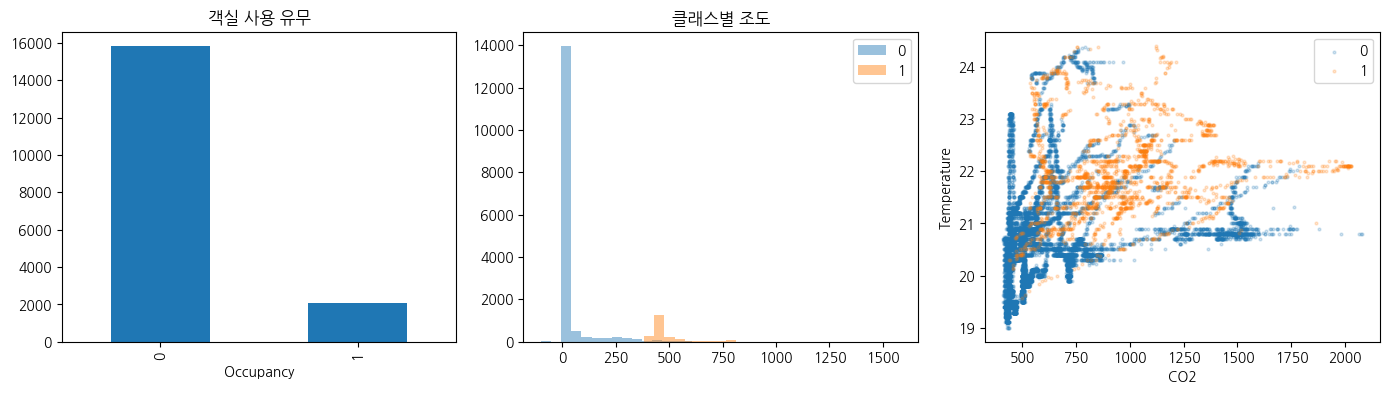

,Temperature,Humidity,Light,CO2,HumidityRatio
Temperature,1.000000,-0.199284,0.625230,0.399370,0.138071
Humidity,-0.199284,1.000000,-0.052119,0.254446,0.941568
Light,0.625230,-0.052119,1.000000,0.354062,0.163272
CO2,0.399370,0.254446,0.354062,1.000000,0.409735
HumidityRatio,0.138071,0.941568,0.163272,0.409735,1.000000


In [2]:
set_question('1-1')
occupancy=load('problem1.csv');occupancy['date']=pd.to_datetime(occupancy.date);occupancy=occupancy.sort_values('date').reset_index(drop=True)
quality(occupancy)
features=['Temperature','Humidity','Light','CO2','HumidityRatio']
fig,axs=plt.subplots(1,3,figsize=(14,4));occupancy.Occupancy.value_counts().sort_index().plot.bar(ax=axs[0],title='객실 사용 유무')
for label,g in occupancy.groupby('Occupancy'):
    axs[1].hist(g.Light,bins=35,alpha=.45,label=str(label));axs[2].scatter(g.CO2,g.Temperature,s=4,alpha=.2,label=str(label))
axs[1].set_title('클래스별 조도');axs[1].legend();axs[2].set(xlabel='CO2',ylabel='Temperature');axs[2].legend();fig.tight_layout();plt.show()
display(occupancy[features].corr())

### 1-2

센서 결측을 처리할 방안을 선정하고 근거를 제시하시오. 시간순 학습·검증·시험을 고정하고 대치 기준을 학습 자료에만 적합하시오.

**판단 및 풀이 근거**

정확히 같은 행의 중복만 제거하고 동일 시각에 다른 내용이 있는 경우를 보고합니다. 시간 순으로 고유 시각을 60/20/20으로 나눠 같은 시각의 기록이 여러 구간에 걸치지 않도록 합니다. 숫자형 결측은 train 중앙값으로 대치하고 train 표준편차로 스케일링합니다. 실제 결측이 없으면 대치가 불필요함도 확인합니다.

**실행 답안**

아래 코드는 이 문항의 산출물과 수치를 계산합니다. 결과와 위 판단 근거를 연결해 답안을 작성합니다.

In [3]:
set_question('1-2')
occupancy=occupancy.drop_duplicates().sort_values('date').reset_index(drop=True)
unique_times=occupancy.date.drop_duplicates().to_numpy();t1=unique_times[int(len(unique_times)*.6)];t2=unique_times[int(len(unique_times)*.8)]
train_mask=(occupancy.date<t1).to_numpy();valid_mask=((occupancy.date>=t1)&(occupancy.date<t2)).to_numpy();test_mask=(occupancy.date>=t2).to_numpy()
X=occupancy[features];y=occupancy.Occupancy.to_numpy()
preprocess=Pipeline([('impute',SimpleImputer(strategy='median')),('scale',StandardScaler())])
train_values=preprocess.fit_transform(X[train_mask]);valid_values=preprocess.transform(X[valid_mask]);test_values=preprocess.transform(X[test_mask])
display(pd.DataFrame({'feature':features,'train_median':preprocess.named_steps['impute'].statistics_,'missing':X.isna().sum().to_numpy()}))
assert occupancy.date[train_mask].max()<occupancy.date[valid_mask].min()<occupancy.date[test_mask].min()
print('시간 순 분할:',int(train_mask.sum()),int(valid_mask.sum()),int(test_mask.sum()))

,feature,train_median,missing
0,Temperature,20.600000,0
1,Humidity,25.390000,0
2,Light,0.000000,0
3,CO2,463.500000,21
4,HumidityRatio,0.003805,0


시간 순 분할: 10746 3582 3582


### 1-3

중복 시각·센서 범위·상충 라벨 등을 점검하시오. 운영 중 지속해서 확인할 품질 항목과 대응 방안을 제시하시오.

**판단 및 풀이 근거**

중복 타임스탬프·센서 범위·일자별 표본 간격·동일 특성의 상충 라벨을 검사합니다. 조도·CO2의 큰 값은 사용 중 상태의 정상 신호일 수 있어 일괄 제거하지 않습니다. 운영 시 센서 교정·결측률·범위·이상 시각·입력 분포·시간별 성능을 모니터링하고, 라벨 작성 규칙과 데이터 버전을 관리하는 방안을 제안합니다.

**실행 답안**

아래 코드는 이 문항의 산출물과 수치를 계산합니다. 결과와 위 판단 근거를 연결해 답안을 작성합니다.

In [4]:
set_question('1-3')
print('중복 시간 기록:',int(occupancy.date.duplicated().sum()))
print('일자별 관측수:');display(occupancy.groupby(occupancy.date.dt.date).size().to_frame('rows'))
print('물리 범위 후보: Humidity 밖:',int((~occupancy.Humidity.between(0,100)).sum()),
      '음수 Light:',int((occupancy.Light<0).sum()),'음수 CO2:',int((occupancy.CO2<0).sum()))
conflicting=occupancy.groupby(['date']+features,dropna=False).Occupancy.nunique()
print('같은 시간·같은 특성인데 라벨이 다른 조합:',int((conflicting>1).sum()))

중복 시간 기록: 0
일자별 관측수:


,rows
date,
2015-02-02,477
2015-02-03,1096
2015-02-04,915
2015-02-05,1167
2015-02-06,1102
2015-02-07,1440
2015-02-08,1440
2015-02-09,1132
2015-02-10,541


물리 범위 후보: Humidity 밖: 0 음수 Light: 50 음수 CO2: 0
같은 시간·같은 특성인데 라벨이 다른 조합: 0


### 2-1

원자료와 학습 자료의 클래스 비율을 확인하시오. 불균형 정도를 판단한 근거와 단순 정확도의 한계를 설명하시오.

**판단 및 풀이 근거**

원자료와 train의 양성 비율·다수/소수 비율을 계산합니다. 이진 클래스가 완전히 균형인지와 불균형의 정도를 수치로 설명하고, accuracy만으로 다수 클래스 예측 모델이 좋아 보일 수 있음을 확인합니다. 실제 운영 오류 비용과 PR-AUC/F1도 판단에 필요합니다.

**실행 답안**

아래 코드는 이 문항의 산출물과 수치를 계산합니다. 결과와 위 판단 근거를 연결해 답안을 작성합니다.

In [5]:
set_question('2-1')
counts=pd.Series(y[train_mask]).value_counts().sort_index();distribution=pd.DataFrame({'count':counts,'ratio':counts/counts.sum()});display(distribution)
print('train 다수/소수 비율:',counts.max()/counts.min())
print('다수 클래스만 예측하는 train accuracy:',counts.max()/counts.sum())

,count,ratio
0,9330,0.86823
1,1416,0.13177


train 다수/소수 비율: 6.588983050847458
다수 클래스만 예측하는 train accuracy: 0.8682300390843104


### 2-2

소수 상태를 보완할 두 표본 증가 방안을 선택하시오. 실제 센서 조합 보존·다양성·과적합 관점에서 선정 근거와 장단점을 비교하시오.

**판단 및 풀이 근거**

RandomOverSampler와 SMOTE를 비교합니다. 전자는 기존 소수 표본을 복제하므로 센서 값의 실제 조합을 유지하지만 과적합 우려가 있고, 후자는 근방에서 합성해 다양성을 늘리지만 물리적으로 부자연스러운 조합과 경계 혼합을 만들 수 있습니다. SMOTE는 표준화된 train 좌표에서 수행합니다.

**실행 답안**

아래 코드는 이 문항의 산출물과 수치를 계산합니다. 결과와 위 판단 근거를 연결해 답안을 작성합니다.

In [6]:
set_question('2-2')
samplers={'ROS':RandomOverSampler(random_state=SEED),'SMOTE':SMOTE(random_state=SEED,k_neighbors=5)}
print('선정:',list(samplers),'SMOTE 입력 좌표는 train 표준화 특성')

선정: ['ROS', 'SMOTE'] SMOTE 입력 좌표는 train 표준화 특성


### 2-3

선택한 두 방법을 학습 자료에만 적용하시오. 전후 표본 수·클래스 비율·값 범위를 확인하고, 균형 달성과 실제 성능 향상을 구분하시오.

**판단 및 풀이 근거**

원본 train·ROS train·SMOTE train의 클래스 개수와 표본 수를 비교합니다. 유한성·피처 수·균형 목표를 검증하고, 원 단위로 역변환해 합성 자료의 습도·조도·CO2 범위도 확인합니다. 수량 균형 달성은 검증되지만 예측 성능 개선 여부는 원 비율을 유지한 validation/test 결과로 판단해야 합니다.

**실행 답안**

아래 코드는 이 문항의 산출물과 수치를 계산합니다. 결과와 위 판단 근거를 연결해 답안을 작성합니다.

In [7]:
set_question('2-3')
training_sets={'original':(train_values,y[train_mask])}
for name,sampler_est in samplers.items():
    tx,ty=sampler_est.fit_resample(train_values,y[train_mask]);training_sets[name]=(tx,ty)
    assert np.isfinite(tx).all() and tx.shape[1]==len(features) and pd.Series(ty).value_counts().nunique()==1
sample_summary=pd.DataFrame({name:pd.Series(ty).value_counts() for name,(tx,ty) in training_sets.items()});display(sample_summary)
restored=preprocess.named_steps['scale'].inverse_transform(training_sets['SMOTE'][0]);restored=pd.DataFrame(restored,columns=features)
display(restored.agg(['min','max']))
print('합성 후 비물리 후보: 습도',int((~restored.Humidity.between(0,100)).sum()),'음수 조도',int((restored.Light<0).sum()),'음수 CO2',int((restored.CO2<0).sum()))

,original,ROS,SMOTE
0,9330,9330,9330
1,1416,9330,9330


,Temperature,Humidity,Light,CO2,HumidityRatio
min,19.000000,16.7450,-99.0,412.75,0.002674
max,24.408333,39.1175,1581.0,2028.25,0.006461


합성 후 비물리 후보: 습도 0 음수 조도 50 음수 CO2 0


### 3-1

빠른 운영을 위한 후보와 복잡한 관계를 포착할 후보를 각각 선택하고 근거를 제시하시오. 속도와 정확도의 우열을 실행 전 단정하지 마시오.

**판단 및 풀이 근거**

속도 후보로 Logistic Regression, 정확도 후보로 Random Forest를 사용합니다. 로지스틱 회귀는 저차원 선형 결정 경계를 빠르게 추정하고, Random Forest는 비선형·교호작용을 포착합니다. 실제 데이터에서는 조도처럼 매우 강한 변수 때문에 선형 모형도 충분히 정확할 수 있으므로 측정 결과로 판단합니다.

**실행 답안**

아래 코드는 이 문항의 산출물과 수치를 계산합니다. 결과와 위 판단 근거를 연결해 답안을 작성합니다.

In [8]:
set_question('3-1')
estimators={'Logistic':LogisticRegression(max_iter=2000,random_state=SEED),
            'RandomForest':RandomForestClassifier(n_estimators=120,max_depth=12,min_samples_leaf=2,random_state=SEED,n_jobs=1)}
print('모델 후보:',list(estimators))

모델 후보: ['Logistic', 'RandomForest']


### 3-2

원본 학습 자료와 두 보완 자료에 두 모형을 적용한 6개 조합을 동일 검증 구간에서 비교하시오. 선택 지표·학습 및 예측 시간·최종 시험 결과를 보고하시오.

**판단 및 풀이 근거**

원본·ROS·SMOTE 각 train에 모델 2개를 적합하여 총 6개 조합의 validation 성능·학습 시간·예측 시간을 비교합니다. balanced accuracy·macro F1·ROC-AUC·Average Precision을 함께 보고합니다. 양성 1에 대한 validation F1이 가장 높은 조합을 정한 뒤 그 조합의 최종 test만 평가합니다. 예측 임계값은 기본 0.5로 고정합니다.

**실행 답안**

아래 코드는 이 문항의 산출물과 수치를 계산합니다. 결과와 위 판단 근거를 연결해 답안을 작성합니다.

Accuracy  BalancedAccuracy  F1_macro  F1_weighted  \
sampling model                                                             
original Logistic      0.992741          0.991785  0.969302     0.992906   
         RandomForest  0.988833          0.994060  0.954459     0.989275   
ROS      Logistic      0.988275          0.993763  0.952370     0.988760   
         RandomForest  0.986320          0.992723  0.945187     0.986970   
SMOTE    Logistic      0.989112          0.994208  0.955510     0.989533   
         RandomForest  0.986320          0.992723  0.945187     0.986970   

                        ROC_AUC  AveragePrecision  F1_positive  fit_seconds  \
sampling model                                                                
original Logistic      0.996718          0.926834     0.942478     0.012432   
         RandomForest  0.997498          0.942443     0.914894     1.613905   
ROS      Logistic      0.996762          0.927856     0.911017     0.030085   
         RandomForest  0.995829          0.887532     0.897704     3.244459   
SMOTE    Logistic      0.996739          0.927240     0.916844     0.033054   
         RandomForest  0.995222          0.877778     0.897704     3.298227   

                       predict_seconds  
sampling model                          
original Logistic             0.000081  
         RandomForest         0.032310  
ROS      Logistic             0.000107  
         RandomForest         0.034639  
SMOTE    Logistic             0.000168  
         RandomForest         0.017015

validation 양성 F1 선택: ('original', 'Logistic')


Accuracy            0.993579
BalancedAccuracy    0.995400
F1_macro            0.986155
F1_weighted         0.993638
ROC_AUC             0.996627
AveragePrecision    0.987082
Name: 선택 조합 최종 test, dtype: float64

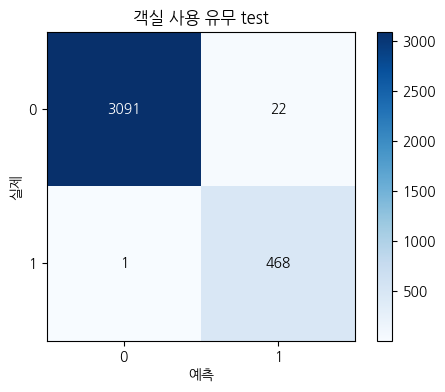

,0,1
0,3091,22
1,1,468


In [9]:
set_question('3-2')
models={};rows=[]
for sampling,(tx,ty) in training_sets.items():
    for name,est in estimators.items():
        model=clone(est);start=time.perf_counter();model.fit(tx,ty);elapsed=time.perf_counter()-start
        pred=model.predict(valid_values);prob=model.predict_proba(valid_values)
        rows.append({'sampling':sampling,'model':name,**class_metrics(y[valid_mask],pred,prob),
                     'F1_positive':f1_score(y[valid_mask],pred,zero_division=0),'fit_seconds':elapsed,
                     'predict_seconds':median_predict_time(model,valid_values)})
        models[(sampling,name)]=model
comparison=pd.DataFrame(rows).set_index(['sampling','model']);display(comparison)
selected_key=comparison.F1_positive.idxmax();selected=models[selected_key];test_pred=selected.predict(test_values);test_prob=selected.predict_proba(test_values)
print('validation 양성 F1 선택:',selected_key)
display(pd.Series(class_metrics(y[test_mask],test_pred,test_prob),name='선택 조합 최종 test'))
display(plot_confusion(y[test_mask],test_pred,labels=[0,1],title='객실 사용 유무 test'))
comparison.to_csv(OUT/'객실_6개조합_validation평가.csv')

### 3-3

같은 모형 안에서 표본 구성 전후의 지표 변화와 비용을 비교하시오. 소수 상태 탐지 개선 여부와 운영 도입에 필요한 추가 검증을 설명하시오.

**판단 및 풀이 근거**

리샘플링 전후를 같은 모델·동일 validation에서 비교합니다. 변화량이 양수인지 음수인지 실제 결과로 보고하며, 균형화가 accuracy를 낮추면서 소수 클래스 F1을 높이는 경우도 구분합니다. 복제·합성 표본 증가에 따른 학습 비용도 함께 설명합니다. 시간 구간 분포가 다르면 과거의 class prior를 인위적으로 바꾸는 것이 미래 성능을 악화시킬 수 있습니다.

**실행 답안**

아래 코드는 이 문항의 산출물과 수치를 계산합니다. 결과와 위 판단 근거를 연결해 답안을 작성합니다.

Logistic 원본 대비 변화


,Accuracy,F1_positive,AveragePrecision,fit_seconds
sampling,,,,
original,0.000000,0.000000,0.000000,0.000000
ROS,-0.004467,-0.031461,0.001022,0.017653
SMOTE,-0.003629,-0.025634,0.000406,0.020622


RandomForest 원본 대비 변화


,Accuracy,F1_positive,AveragePrecision,fit_seconds
sampling,,,,
original,0.000000,0.00000,0.000000,0.000000
ROS,-0.002513,-0.01719,-0.054910,1.630554
SMOTE,-0.002513,-0.01719,-0.064665,1.684322


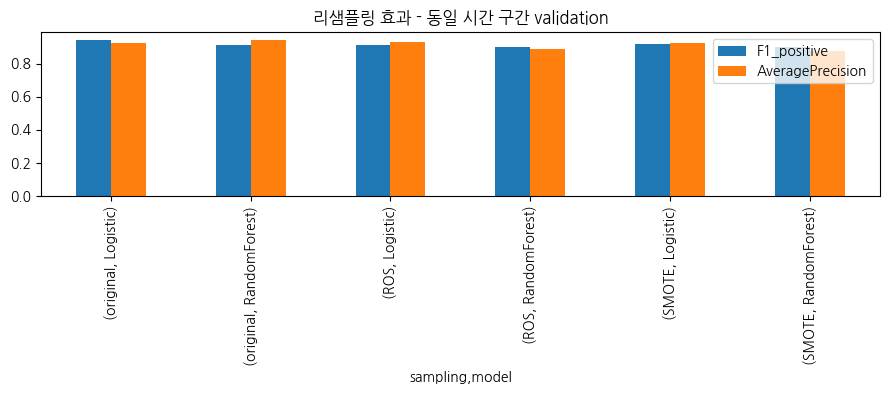

In [10]:
set_question('3-3')
for name in estimators:
    baseline=comparison.loc[('original',name)]
    delta=comparison.xs(name,level='model')[['Accuracy','F1_positive','AveragePrecision','fit_seconds']]-baseline[['Accuracy','F1_positive','AveragePrecision','fit_seconds']]
    print(name,'원본 대비 변화');display(delta)
fig,ax=plt.subplots(figsize=(9,4));comparison[['F1_positive','AveragePrecision']].plot.bar(ax=ax);ax.set_title('리샘플링 효과 - 동일 시간 구간 validation');fig.tight_layout();plt.show()

## 2. 진공관 수명 주장 평가

공장은 진공관 수명의 중앙값이 10,000시간이라고 주장한다. 품질팀은 독립 표본 12개의 수명을 수집했으나 정규성·분포 대칭성은 가정하기 어렵다. 중앙값이 기준과 다른지 유의수준 5%에서 판단한다.

자료: problem2.csv

### 통계 2-1

조사 목적과 자료의 분포 가정에 적절한 검정 방법을 선택하고 근거를 설명하시오. 귀무가설과 대립가설을 모수와 함께 작성하시오.

**판단 및 풀이 근거**

중앙값 m에 대해 H0: m=10,000시간, H1: m≠10,000시간의 양측 부호 검정을 기본으로 사용합니다. 분포의 정규성을 요구하지 않지만 독립 표본을 가정합니다. 공장의 최소 수명 주장에 대한 미달 검정이 목적이라면 H1: m<10,000의 단측 검정을 별도로 구분합니다.

**실행 답안**

아래 코드는 이 문항의 산출물과 수치를 계산합니다. 결과와 위 판단 근거를 연결해 답안을 작성합니다.

In [11]:
set_question('통계 2-1')
lifetimes=load('problem2.csv');values=lifetimes['life span'].to_numpy();display(lifetimes)
print('H0: median=10000, H1: median != 10000; alpha=.05')

,name,life span
0,sample1,10000
1,sample2,9000
2,sample3,9500
3,sample4,10000
4,sample5,10000
5,sample6,8900
6,sample7,9900
7,sample8,10100
8,sample9,10300
9,sample10,10020


H0: median=10000, H1: median != 10000; alpha=.05


### 통계 2-2

기준값과 같은 관측과 결측의 처리 원칙을 정하시오. 선택한 검정에 쓰이는 유효 표본 수와 각 방향의 관측 수를 계산하시오.

**판단 및 풀이 근거**

기준값 10,000과 같은 표본은 부호가 없으므로 제외합니다. 결측이 있는 경우 먼저 보고하고 제외합니다. 유효 표본 수는 10,000보다 작거나 큰 관측의 개수입니다.

**실행 답안**

아래 코드는 이 문항의 산출물과 수치를 계산합니다. 결과와 위 판단 근거를 연결해 답안을 작성합니다.

In [12]:
set_question('통계 2-2')
values=values[np.isfinite(values)];differences=values-10000
positive=int((differences>0).sum());negative=int((differences<0).sum());ties=int((differences==0).sum());effective=positive+negative
assert effective>0
print('전체 유한 관측:',len(values),'동점:',ties,'양의 부호:',positive,'음의 부호:',negative,'유효 n:',effective)

전체 유한 관측: 12 동점: 4 양의 부호: 3 음의 부호: 5 유효 n: 8


### 통계 2-3

검정통계량과 정확 양측 p-value를 계산하고 기각 여부·수명 주장에 대한 결론을 작성하시오. 수명 미달만 조사하는 경우의 단측 가설과 별도로 비교하시오.

**판단 및 풀이 근거**

정규성·대칭성을 요구하지 않는 독립 수명 표본의 중앙값 검정이므로 정확 부호 검정을 선택한다. 동점 제외 후 S+~Binomial(n_eff,.5)이며 기본 양측과 미달 단측을 분리한다.

**계산·해석 상세**

H0에서 양의 부호 수 S+는 Binomial(n_eff,0.5)입니다. S+와 min(S+,S−)를 모두 제시하고 정확 양측 이항 p값으로 판단합니다. 미달 방향의 단측 p값은 보조로 보고하며 양측과 혼동하지 않습니다.

**실행 답안**

아래 코드는 이 문항의 산출물과 수치를 계산합니다. 가설·통계량·p-value·기각 여부·상황 결론을 함께 출력하며 수치는 실행 결과에 따라 결정합니다.

In [13]:
set_question('통계 2-3')
two=stats.binomtest(positive,effective,p=.5,alternative='two-sided');lower=stats.binomtest(positive,effective,p=.5,alternative='less')
display(pd.Series({'S_plus':positive,'S_minus':negative,'min_sign_statistic':min(positive,negative),
                   'n_effective':effective,'two_sided_p':two.pvalue,'lower_sided_p':lower.pvalue}))
print('기본 양측 결론:',decision(two.pvalue));print('수명 미달 단측 결론:',decision(lower.pvalue))

# 상황형 요구: 가설·실제 수치·기각 여부·맥락 결론
report_test('정확 부호 검정 양측','수명 중앙값=10000','수명 중앙값 != 10000',positive,two.pvalue,'진공관 수명 중앙값이 10000시간과 다르다','독립 관측·기준값 동점 제외. 평균 수명의 검정이 아니다.')
report_test('보조: 정확 부호 검정 미달 단측','수명 중앙값 >= 10000','수명 중앙값 < 10000',positive,lower.pvalue,'수명 중앙값이 10000시간 미만이다','방향은 사전 지정; 기본 양측 검정과 별개.')

S_plus                3.000000
S_minus               5.000000
min_sign_statistic    3.000000
n_effective           8.000000
two_sided_p           0.726562
lower_sided_p         0.363281
dtype: float64

기본 양측 결론: 귀무가설을 기각할 근거 부족
수명 미달 단측 결론: 귀무가설을 기각할 근거 부족
{
  "question": "통계 2-3",
  "method": "정확 부호 검정 양측",
  "H0": "수명 중앙값=10000",
  "H1": "수명 중앙값 != 10000",
  "statistic": 3.0,
  "p_value": 0.7265625,
  "alpha": 0.05,
  "reject_H0": false,
  "assumptions": "독립 관측·기준값 동점 제외. 평균 수명의 검정이 아니다.",
  "conclusion": "귀무가설을 기각하지 못한다. 진공관 수명 중앙값이 10000시간과 다르다는 통계적 근거가 충분하지 않다. 귀무가설의 참을 입증한 것은 아니다."
}
{
  "question": "통계 2-3",
  "method": "보조: 정확 부호 검정 미달 단측",
  "H0": "수명 중앙값 >= 10000",
  "H1": "수명 중앙값 < 10000",
  "statistic": 3.0,
  "p_value": 0.36328125,
  "alpha": 0.05,
  "reject_H0": false,
  "assumptions": "방향은 사전 지정; 기본 양측 검정과 별개.",
  "conclusion": "귀무가설을 기각하지 못한다. 수명 중앙값이 10000시간 미만이다는 통계적 근거가 충분하지 않다. 귀무가설의 참을 입증한 것은 아니다."
}


## 3. 국가별 감염 패턴 비교

국가·날짜별 신규 확진자 자료로 국가 간 시간 패턴을 비교하려 한다. 미보고 값이 0명이라는 보장은 없다. 이 대문항은 수명 표본과 다른 시계열 자료다.

자료: problem3_covid2.csv

### 통계 3-1

국가·날짜 중복과 누락을 확인한 후 국가별 관측 기간 누적 확진자 표를 구성하시오. 미보고 처리 방식이 누적값의 의미에 주는 영향을 설명하시오.

**판단 및 풀이 근거**

location·date로 정렬한 뒤 각 나라 안에서 new_cases를 누적합합니다. 원자료 신규 값의 결측 233건은 실제 0으로 단정하지 않습니다. 계산용으로 결측의 기여분을 0으로 두고 보고된 값만 누적하며, 원래 결측 표시를 별도 열에 보존합니다. 이는 미보고분을 알 수 없는 보고값 누계이며 전체 실제 발생 누계가 아닙니다. 이 누적값은 제공된 관측 기간 시작부터의 합이며 팬데믹 시작 이후 전체 누적과 동일하다고 주장하지 않습니다. 소급 수정에 따른 음수 신규 값이 있으면 원자료를 임의로 0으로 바꾸지 않고 그대로 누적하고 건수를 보고합니다.

**실행 답안**

아래 코드는 이 문항의 산출물과 수치를 계산합니다. 결과와 위 판단 근거를 연결해 답안을 작성합니다.

In [14]:
set_question('통계 3-1')
case_data=load('problem3_covid2.csv');case_data['date']=pd.to_datetime(case_data.date);case_data=case_data.sort_values(['location','date'])
assert not case_data.duplicated(['location','date']).any()
case_data['missing_report']=case_data.new_cases.isna()
print('신규 값 결측:',int(case_data.missing_report.sum()),'미보고분은 계산상 0 기여; 실제 0으로 단정하지 않음')
case_data['cumulative_cases']=case_data.new_cases.fillna(0).groupby(case_data.location).cumsum()
display(case_data.head());print('음수 신규 값:',int((case_data.new_cases<0).sum()))
cumulative=case_data.pivot(index='date',columns='location',values='cumulative_cases').sort_index()
assert cumulative.notna().all().all()
case_data.to_csv(OUT/'국가별_기간누적확진자.csv',index=False);display(cumulative.head())

신규 값 결측: 233 미보고분은 계산상 0 기여; 실제 0으로 단정하지 않음


,location,date,new_cases,missing_report,cumulative_cases
0,Austria,2021-01-01,2096.0,False,2096.0
1,Austria,2021-01-02,1391.0,False,3487.0
2,Austria,2021-01-03,1466.0,False,4953.0
3,Austria,2021-01-04,1642.0,False,6595.0
4,Austria,2021-01-05,2311.0,False,8906.0


음수 신규 값: 0


location,Austria,Bangladesh,Bhutan,Chile,Colombia,Costa Rica,...,Saint Pierre and Miquelon,Slovenia,Solomon Islands,Tunisia,Uruguay,Vanuatu
date,,,,,,,,,,,,,
2021-01-01,2096.0,990.0,19.0,3591.0,12105.0,0.0,...,0.0,1798.0,0.0,1417.0,634.0,0.0
2021-01-02,3487.0,1674.0,40.0,6929.0,23633.0,0.0,...,0.0,2191.0,0.0,2839.0,1156.0,0.0
2021-01-03,4953.0,2509.0,46.0,9218.0,33045.0,0.0,...,0.0,2934.0,0.0,4404.0,1704.0,0.0
2021-01-04,6595.0,3419.0,64.0,11668.0,43356.0,3115.0,...,0.0,3706.0,0.0,5656.0,2307.0,0.0
2021-01-05,8906.0,4410.0,64.0,14128.0,60191.0,4270.0,...,0.0,6218.0,0.0,7921.0,2985.0,0.0


### 통계 3-2

각 국가 누적 시계열의 lag 1~50 자기상관을 특성으로 구성하시오. 국가 간 유클리디안 거리 기반 계층 구조를 덴드로그램으로 나타내고 비정상 누적 시계열을 비교할 때의 한계를 설명하시오.

**판단 및 풀이 근거**

각 나라 누적 시계열의 ACF lag 1~50을 50차원 특성으로 만듭니다. lag 0은 제외합니다. 국가별 동일한 연속 일자 격자를 확인하고 유클리드 거리와 Ward 계층적 군집으로 덴드로그램을 만듭니다. 누계는 앞 문항의 미보고분 처리 가정에 영향을 받으므로 자료 품질의 한계를 함께 보고합니다. ACF가 정의되지 않는 상수 시계열은 제외·보고합니다. 누적 시계열의 공통 추세가 비슷한 ACF를 만들 수 있어 이것을 감염 원인이나 확진자 규모의 동등성으로 해석하지 않습니다.

**실행 답안**

아래 코드는 이 문항의 산출물과 수치를 계산합니다. 결과와 위 판단 근거를 연결해 답안을 작성합니다.

ACF 제외 국가: []


,lag_1,lag_2,lag_3,lag_4,lag_5,lag_6,...,lag_45,lag_46,lag_47,lag_48,lag_49,lag_50
Austria,0.986910,0.973895,0.961027,0.948347,0.935884,0.923563,...,0.475543,0.464370,0.453267,0.442242,0.431334,0.420483
Bangladesh,0.993958,0.987757,0.981401,0.974895,0.968240,0.961439,...,0.601019,0.590035,0.579005,0.567934,0.556820,0.545668
Bhutan,0.994586,0.989147,0.983590,0.977976,0.972226,0.966459,...,0.662047,0.652165,0.642174,0.632091,0.621911,0.611642
Chile,0.992455,0.984846,0.977165,0.969415,0.961598,0.953711,...,0.609285,0.599527,0.589710,0.579831,0.569911,0.559947
Colombia,0.993340,0.986596,0.979760,0.972838,0.965857,0.958820,...,0.643029,0.633751,0.624406,0.615000,0.605532,0.596002


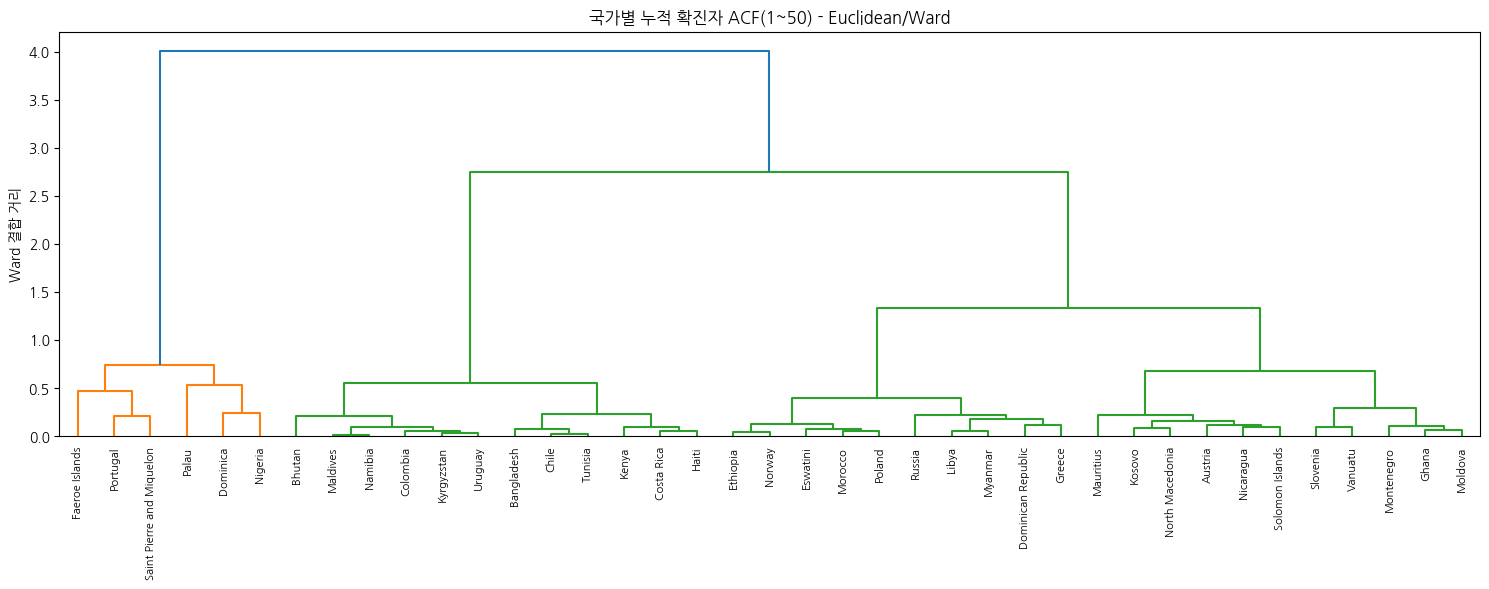

In [15]:
set_question('통계 3-2')
from statsmodels.tsa.stattools import acf
from scipy.cluster.hierarchy import linkage,dendrogram
assert len(cumulative)>50
assert (cumulative.index.to_series().diff().dropna()==pd.Timedelta(days=1)).all()
acf_rows={};excluded=[]
for country in cumulative.columns:
    series=cumulative[country].to_numpy()
    if np.std(series)==0:excluded.append(country);continue
    values=acf(series,nlags=50,fft=True)[1:51]
    if not np.isfinite(values).all():excluded.append(country);continue
    acf_rows[country]=values
acf_features=pd.DataFrame.from_dict(acf_rows,orient='index',columns=['lag_'+str(i) for i in range(1,51)])
assert acf_features.shape[1]==50 and len(acf_features)>=2
print('ACF 제외 국가:',excluded);display(acf_features.head())
Z=linkage(acf_features.to_numpy(),method='ward',metric='euclidean')
fig,ax=plt.subplots(figsize=(15,6));dendrogram(Z,labels=acf_features.index.tolist(),leaf_rotation=90,ax=ax)
ax.set(title='국가별 누적 확진자 ACF(1~50) - Euclidean/Ward',ylabel='Ward 결합 거리');fig.tight_layout();plt.show()
acf_features.to_csv(OUT/'국가별_ACF_lag1_50.csv')

## 4. 학과와 성적 구간

학생을 독립적으로 조사해 학과×학점 구간별 인원수를 집계한 표다. 각 학생은 하나의 셀에만 속한다. 학과에 따라 성적 구간 분포가 다른지 유의수준 5%에서 판단한다.

자료: 본문 인원수 표

| score | 사회학과 | 자연과학 | 공학 |
| --- | --- | --- | --- |
| 1.5-2.5 | 15 | 25 | 10 |
| 2.5-3.5 | 60 | 69 | 77 |
| 3.5-4.5 | 24 | 5 | 13 |

### 통계 4-1

변수의 척도와 표의 구조에 적절한 검정 방법을 선택하고 근거를 설명하시오. 귀무가설과 대립가설을 작성하시오.

**판단 및 풀이 근거**

H0: 학과와 성적 구간은 독립이다. H1: 학과와 성적 구간 사이에 연관성이 있다. 빈도 자료의 독립성 카이제곱 검정을 수행하며 각 학생이 한 셀에만 속하는 독립 관측이라고 가정합니다.

**실행 답안**

아래 코드는 이 문항의 산출물과 수치를 계산합니다. 결과와 위 판단 근거를 연결해 답안을 작성합니다.

In [16]:
set_question('통계 4-1')
observed=pd.DataFrame([[15,25,10],[60,69,77],[24,5,13]],index=['1.5-2.5','2.5-3.5','3.5-4.5'],columns=['사회학과','자연과학','공학'])
display(observed);print('전체 인원:',observed.to_numpy().sum())

,사회학과,자연과학,공학
1.5-2.5,15,25,10
2.5-3.5,60,69,77
3.5-4.5,24,5,13


전체 인원: 298


### 통계 4-2

귀무가설 하 각 셀의 기대 인원수를 계산하고 검정의 근사 조건을 확인하시오.

**판단 및 풀이 근거**

독립일 때 E_ij=(i행 합×j열 합)/전체합입니다. 기대도수 표를 직접 계산하고 scipy의 결과와 일치하는지 검증합니다. 기대도수가 충분히 크다는 근사 조건도 확인합니다.

**실행 답안**

아래 코드는 이 문항의 산출물과 수치를 계산합니다. 결과와 위 판단 근거를 연결해 답안을 작성합니다.

In [17]:
set_question('통계 4-2')
total=observed.to_numpy().sum();expected=np.outer(observed.sum(axis=1),observed.sum(axis=0))/total
expected_table=pd.DataFrame(expected,index=observed.index,columns=observed.columns);display(expected_table)
print('최소 기대도수:',expected.min(),'5 미만 셀:',int((expected<5).sum()))

,사회학과,자연과학,공학
1.5-2.5,16.610738,16.610738,16.778523
2.5-3.5,68.436242,68.436242,69.127517
3.5-4.5,13.953020,13.953020,14.093960


최소 기대도수: 13.953020134228188 5 미만 셀: 0


### 통계 4-3

통계량·자유도·p-value·기각 여부와 학과-성적 관계의 결론을 제시하시오. 관계의 크기와 인과 해석의 한계도 설명하시오.

**판단 및 풀이 근거**

서로 다른 학생의 두 범주 변수 교차 빈도이므로 독립성 카이제곱 검정을 선택한다. H0: 학과와 성적 구간은 독립, H1: 연관성이 존재. 기대도수 조건과 효과 크기를 함께 본다.

**계산·해석 상세**

χ²=Σ(O−E)²/E, 자유도=(3−1)(3−1)=4입니다. p값으로 0.05 수준의 기각 여부를 결정하고 연관 크기 Cramér V도 제시합니다. 연관성이 유의하더라도 학과가 성적을 인과적으로 결정한다는 결론은 아닙니다.

**실행 답안**

아래 코드는 이 문항의 산출물과 수치를 계산합니다. 가설·통계량·p-value·기각 여부·상황 결론을 함께 출력하며 수치는 실행 결과에 따라 결정합니다.

In [18]:
set_question('통계 4-3')
manual_stat=float(((observed.to_numpy()-expected)**2/expected).sum())
chi2,pvalue,degrees,scipy_expected=stats.chi2_contingency(observed,correction=False)
np.testing.assert_allclose(expected,scipy_expected);assert np.isclose(manual_stat,chi2) and degrees==4
cramers_v=np.sqrt(chi2/(total*min(observed.shape[0]-1,observed.shape[1]-1)))
display(pd.Series({'chi2':chi2,'df':degrees,'p_value':pvalue,'Cramers_V':cramers_v}))
print('결론:',decision(pvalue));expected_table.to_csv(OUT/'학과_성적_기대도수.csv')

# 상황형 요구: 가설·실제 수치·기각 여부·맥락 결론
report_test('범주 독립성 카이제곱','학과와 성적 구간이 독립이다','학과와 성적 구간이 연관된다',chi2,pvalue,'학과와 성적 구간 사이에 연관성이 있다','독립 학생·1명 1셀·기대도수 조건 충족. 인과가 아님.',df=degrees)

chi2         22.136920
df            4.000000
p_value       0.000188
Cramers_V     0.192724
dtype: float64

결론: 귀무가설 기각
{
  "question": "통계 4-3",
  "method": "범주 독립성 카이제곱",
  "H0": "학과와 성적 구간이 독립이다",
  "H1": "학과와 성적 구간이 연관된다",
  "statistic": 22.136920195949322,
  "p_value": 0.00018822647762421383,
  "alpha": 0.05,
  "reject_H0": true,
  "assumptions": "독립 학생·1명 1셀·기대도수 조건 충족. 인과가 아님.",
  "conclusion": "귀무가설을 기각한다. 학과와 성적 구간 사이에 연관성이 있다는 통계적 근거가 있다.",
  "df": 4
}


## 제출 전 확인

- 문항별 요구 산출물과 수치를 위 결과에서 확인합니다.
- 데이터 변형·모형·지표·가설의 조건을 답안과 함께 제출합니다.
- p ≥ 0.05는 귀무가설이 참임을 입증하는 것이 아니라 기각 근거 부족입니다.
- 모델 선택은 validation 결과로 했으며 최종 test 지표로 재튜닝하지 않습니다.
- 원문 표현의 모호성·자료의 오류는 풀이에서 명시하고 임의로 원문을 수정하지 않았습니다.